# Feature Engineering — Churn Prediction Pipeline

## Purpose
This notebook walks through the feature engineering process step by step,
showing exactly how each raw variable is transformed and what new features
are created based on EDA insights.

The goal is to enrich the dataset with domain knowledge before modelling —
giving the model better signals than the raw data alone.

## New features we will create

| Feature | Logic | Business rationale |
|---|---|---|
| `tenure_group` | Segment tenure into 4 bands | New customers behave differently from loyal ones |
| `services_count` | Sum of contracted services | More services = more integrated = less likely to churn |
| `is_high_value` | MonthlyCharges > median | High-value customers leaving is most costly |
| `has_no_support` | No security AND no tech support | Vulnerable customers with no retention anchor |
| `is_fiber_high_charge` | Fiber optic AND high charge | Highest risk segment identified in EDA |


## 1. Load Raw Data
We start from the raw dataset — exactly as it comes from the source,
before any transformation.

In [3]:
import sys
from pathlib import Path

root = Path("..").resolve()
print(f"Root: {root}")
print(f"src exists: {(root / 'src').exists()}")
print(f"loader exists: {(root / 'src' / 'churn_pipeline' / 'data' / 'loader.py').exists()}")
print(f"__init__ exists: {(root / 'src' / '__init__.py').exists()}")

sys.path.insert(0, str(root))
print(f"\nCurrent sys.path[0]: {sys.path[0]}")

Root: C:\Users\dayana.alconz\churn-prediction-pipeline
src exists: True
loader exists: True
__init__ exists: True

Current sys.path[0]: C:\Users\dayana.alconz\churn-prediction-pipeline


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Add project root to path
root = Path("..").resolve()
sys.path.insert(0, str(root))

from src.churn_pipeline.data.loader import load_raw_data
from src.churn_pipeline.features.engineering import FeatureEngineer

# Colour palette
PALETTE = {"No": "#C9B8D4", "Yes": "#F2C4CE"}
COLORS = ["#C9B8D4", "#F2C4CE"]
SINGLE_COLOR = "#C9B8D4"
BACKGROUND = "#FAF8FB"

DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df_raw = load_raw_data(DATA_PATH)
print(f"Raw data shape: {df_raw.shape}")
print(f"\nKey columns before feature engineering:")
print(df_raw[["tenure", "MonthlyCharges", "InternetService", 
              "OnlineSecurity", "TechSupport", "Churn"]].head(5))

Raw data shape: (7043, 21)

Key columns before feature engineering:
   tenure  MonthlyCharges InternetService OnlineSecurity TechSupport Churn
0       1           29.85             DSL             No          No    No
1      34           56.95             DSL            Yes          No    No
2       2           53.85             DSL            Yes          No   Yes
3      45           42.30             DSL            Yes         Yes    No
4       2           70.70     Fiber optic             No          No   Yes


## 2. Apply Feature Engineering
We now apply the FeatureEngineer transformer to the raw data
and compare before vs after for each new feature.

In [5]:
# Apply feature engineering
fe = FeatureEngineer()
df_engineered = fe.transform(df_raw.copy())

print(f"Shape before: {df_raw.shape}")
print(f"Shape after:  {df_engineered.shape}")
print(f"\nNew columns added: {set(df_engineered.columns) - set(df_raw.columns)}")

Shape before: (7043, 21)
Shape after:  (7043, 26)

New columns added: {'is_high_value', 'is_fiber_high_charge', 'services_count', 'has_no_support', 'tenure_group'}


## 3. Feature by Feature Analysis

### 3.1 tenure_group
Segments customers by seniority. New customers (0-12m) are the most 
vulnerable — we saw in the EDA that churned customers have a median 
tenure of ~10 months.

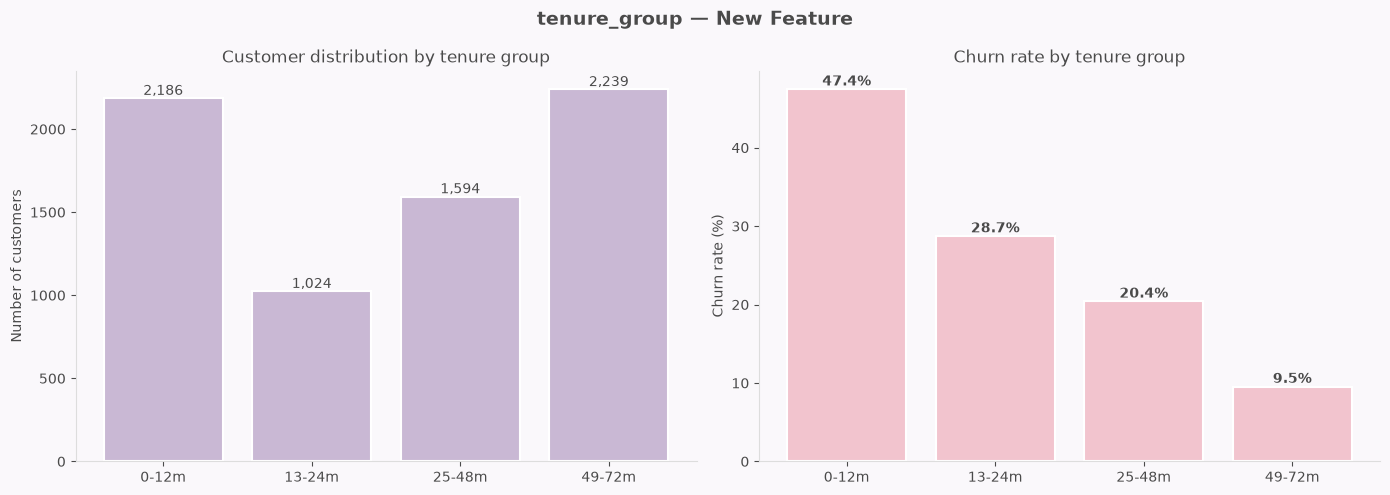


Churn rate by tenure_group:
tenure_group
0-12m     47.4
13-24m    28.7
25-48m    20.4
49-72m     9.5
Name: Churn, dtype: float64


In [6]:
# tenure_group distribution and churn rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=BACKGROUND)
fig.suptitle("tenure_group — New Feature", fontsize=14, fontweight="bold", color="#4A4A4A")

# Distribution
group_counts = df_engineered["tenure_group"].value_counts()
order = ["0-12m", "13-24m", "25-48m", "49-72m"]
group_counts = group_counts.reindex(order)

axes[0].set_facecolor(BACKGROUND)
bars = axes[0].bar(order, group_counts.values, color=SINGLE_COLOR, 
                   edgecolor="white", linewidth=1.5)
axes[0].set_title("Customer distribution by tenure group", fontsize=12, color="#4A4A4A")
axes[0].set_ylabel("Number of customers", color="#4A4A4A")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].spines[["left", "bottom"]].set_color("#DDDDDD")
axes[0].tick_params(colors="#4A4A4A")
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{bar.get_height():,.0f}', ha='center', fontsize=10, color="#4A4A4A")

# Churn rate by group
churn_by_group = df_engineered.groupby("tenure_group")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100).reindex(order)

axes[1].set_facecolor(BACKGROUND)
bars2 = axes[1].bar(order, churn_by_group.values, color=COLORS[1],
                    edgecolor="white", linewidth=1.5)
axes[1].set_title("Churn rate by tenure group", fontsize=12, color="#4A4A4A")
axes[1].set_ylabel("Churn rate (%)", color="#4A4A4A")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].spines[["left", "bottom"]].set_color("#DDDDDD")
axes[1].tick_params(colors="#4A4A4A")
for bar, val in zip(bars2, churn_by_group.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', fontsize=10, 
                 fontweight='bold', color="#4A4A4A")

plt.tight_layout()
plt.savefig("../data/processed/06_tenure_group.png", dpi=150, 
            bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

print("\nChurn rate by tenure_group:")
print(churn_by_group.round(1))

### Findings — tenure_group
- **0-12m: 47.4% churn** — nearly 1 in 2 new customers leave
- **49-72m: 9.5% churn** — loyal customers are 5x less likely to churn
- Clear monotonic relationship: the longer the tenure, the lower the risk
- This feature captures non-linear patterns that raw `tenure` alone may miss

### 3.2 services_count
Total number of contracted services. Hypothesis: customers with more 
services are more integrated with the company and harder to replace.

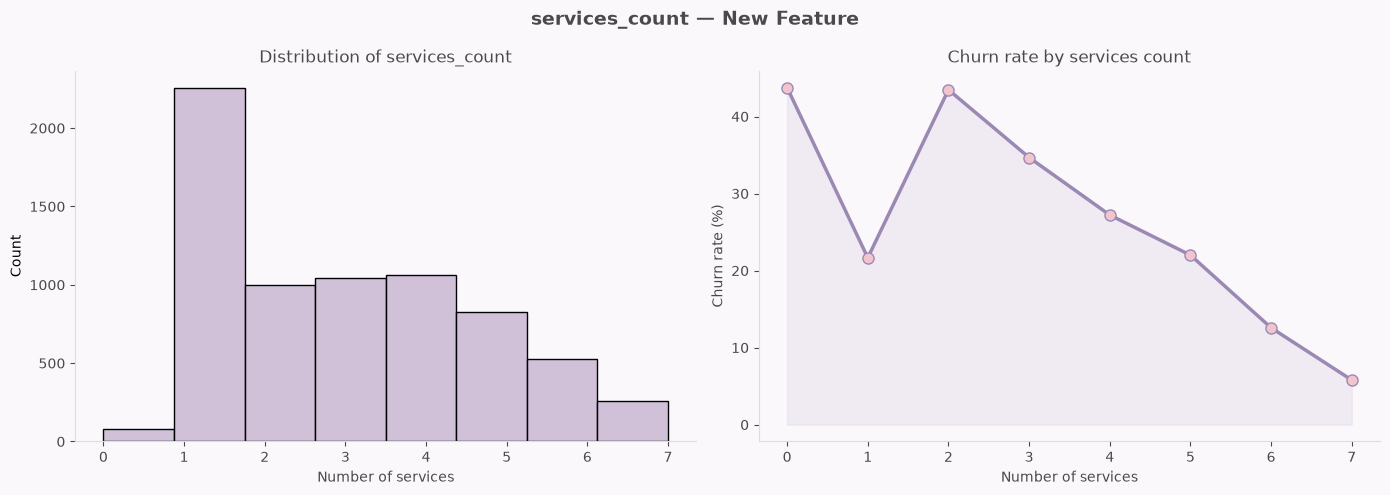


Churn rate by services_count:
services_count
0    43.8
1    21.7
2    43.5
3    34.7
4    27.2
5    22.0
6    12.6
7     5.8
Name: Churn, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=BACKGROUND)
fig.suptitle("services_count — New Feature", fontsize=14, fontweight="bold", color="#4A4A4A")

# Distribution
axes[0].set_facecolor(BACKGROUND)
sns.histplot(data=df_engineered, x="services_count", bins=8,
             color=SINGLE_COLOR, alpha=0.85, ax=axes[0])
axes[0].set_title("Distribution of services_count", fontsize=12, color="#4A4A4A")
axes[0].set_xlabel("Number of services", color="#4A4A4A")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].spines[["left", "bottom"]].set_color("#DDDDDD")
axes[0].tick_params(colors="#4A4A4A")

# Churn rate by services count
churn_by_services = df_engineered.groupby("services_count")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100)

axes[1].set_facecolor(BACKGROUND)
axes[1].plot(churn_by_services.index, churn_by_services.values, 
             color="#9B89B4", linewidth=2.5, marker='o', 
             markersize=8, markerfacecolor=COLORS[1])
axes[1].fill_between(churn_by_services.index, churn_by_services.values,
                     alpha=0.2, color=SINGLE_COLOR)
axes[1].set_title("Churn rate by services count", fontsize=12, color="#4A4A4A")
axes[1].set_xlabel("Number of services", color="#4A4A4A")
axes[1].set_ylabel("Churn rate (%)", color="#4A4A4A")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].spines[["left", "bottom"]].set_color("#DDDDDD")
axes[1].tick_params(colors="#4A4A4A")

plt.tight_layout()
plt.savefig("../data/processed/07_services_count.png", dpi=150,
            bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

print("\nChurn rate by services_count:")
print(churn_by_services.round(1))

### Findings — services_count
- **0 services: 43.8% churn, 7 services: 5.8% churn** — 7.5x difference
- General trend: more services = less churn, confirming the hypothesis
- The spike at services_count=2 (43.5%) is interesting — likely customers 
  with only Phone + Fiber optic (expensive but few retention anchors)
- Customers with 6-7 services are highly integrated — very unlikely to leave
- **This feature captures customer stickiness in a single number**


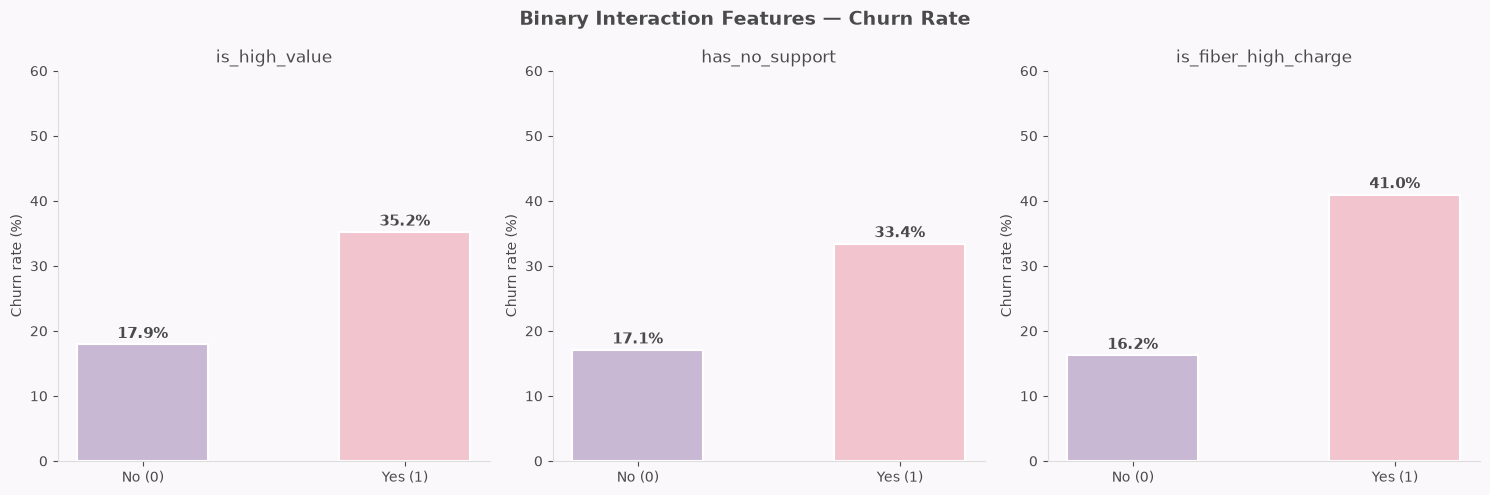


Churn rate by binary features:

is_high_value:
  Flag=0: 17.9% | Flag=1: 35.2% | Difference: +17.3pp

has_no_support:
  Flag=0: 17.1% | Flag=1: 33.4% | Difference: +16.3pp

is_fiber_high_charge:
  Flag=0: 16.2% | Flag=1: 41.0% | Difference: +24.8pp


In [8]:
binary_features = ["is_high_value", "has_no_support", "is_fiber_high_charge"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor=BACKGROUND)
fig.suptitle("Binary Interaction Features — Churn Rate", 
             fontsize=14, fontweight="bold", color="#4A4A4A")

for i, feat in enumerate(binary_features):
    churn_rate = df_engineered.groupby(feat)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100)
    
    axes[i].set_facecolor(BACKGROUND)
    bars = axes[i].bar(["No (0)", "Yes (1)"], churn_rate.values,
                       color=COLORS, edgecolor="white", linewidth=1.5, width=0.5)
    axes[i].set_title(feat, fontsize=12, color="#4A4A4A")
    axes[i].set_ylabel("Churn rate (%)", color="#4A4A4A")
    axes[i].set_ylim(0, 60)
    axes[i].spines[["top", "right"]].set_visible(False)
    axes[i].spines[["left", "bottom"]].set_color("#DDDDDD")
    axes[i].tick_params(colors="#4A4A4A")
    for bar, val in zip(bars, churn_rate.values):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                     f'{val:.1f}%', ha='center', fontsize=11,
                     fontweight='bold', color="#4A4A4A")

plt.tight_layout()
plt.savefig("../data/processed/08_binary_features.png", dpi=150,
            bbox_inches="tight", facecolor=BACKGROUND)
plt.show()

# Summary table
print("\nChurn rate by binary features:")
for feat in binary_features:
    rates = df_engineered.groupby(feat)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100).round(1)
    print(f"\n{feat}:")
    print(f"  Flag=0: {rates[0]}% | Flag=1: {rates[1]}% | Difference: +{rates[1]-rates[0]:.1f}pp")

### Findings — Binary Interaction Features

| Feature | Flag=0 | Flag=1 | Difference |
|---|---|---|---|
| `is_high_value` | 17.9% | 35.2% | +17.3pp |
| `has_no_support` | 17.1% | 33.4% | +16.3pp |
| `is_fiber_high_charge` | 16.2% | 41.0% | +24.8pp |

- **`is_fiber_high_charge`** is the most powerful — customers with Fiber optic 
  AND high charges have 41% churn rate vs 16.2% for the rest. **2.5x more likely to churn**
- **`is_high_value`** confirms that expensive customers are more price-sensitive 
  and more likely to seek alternatives
- **`has_no_support`** identifies vulnerable customers with no retention anchor — 
  no reason to stay when a cheaper alternative appears

All three features add significant signal beyond what raw variables provide individually.

## 4. Summary — Engineered Features Value

All 5 new features show strong discriminative power against churn.
They will be included in the modelling pipeline alongside the original variables.

In [10]:
# Summary comparison: raw tenure vs tenure_group churn rates
summary = pd.DataFrame({
    "Feature": ["tenure_group (0-12m vs 49-72m)", 
                "services_count (0 vs 7)",
                "is_high_value",
                "has_no_support", 
                "is_fiber_high_charge"],
    "Low risk churn rate": ["9.5%", "5.8%", "17.9%", "17.1%", "16.2%"],
    "High risk churn rate": ["47.4%", "43.8%", "35.2%", "33.4%", "41.0%"],
    "Difference": ["+37.9pp", "+38.0pp", "+17.3pp", "+16.3pp", "+24.8pp"]
})

print("Feature Engineering — Value Summary")
print("=" * 60)
print(summary.to_string(index=False))
print("\nAll features validated — ready for modelling pipeline.")

Feature Engineering — Value Summary
                       Feature Low risk churn rate High risk churn rate Difference
tenure_group (0-12m vs 49-72m)                9.5%                47.4%    +37.9pp
       services_count (0 vs 7)                5.8%                43.8%    +38.0pp
                 is_high_value               17.9%                35.2%    +17.3pp
                has_no_support               17.1%                33.4%    +16.3pp
          is_fiber_high_charge               16.2%                41.0%    +24.8pp

All features validated — ready for modelling pipeline.
